In [5]:
!pip install -q kagglehub
import kagglehub, os

path = kagglehub.dataset_download("diegosilvadefrana/fisical-activity-dataset")
print("Saved to:", path)

for root, dirs, files in os.walk(path):
    for f in files:
        full = os.path.join(root, f)
        print(f"{full}  ({os.path.getsize(full)/1e6:.1f} MB)")

100%|██████████| 297M/297M [00:01<00:00, 198MB/s]

Extracting files...


Saved to: /root/.cache/kagglehub/datasets/diegosilvadefrana/fisical-activity-dataset/versions/4
/root/.cache/kagglehub/datasets/diegosilvadefrana/fisical-activity-dataset/versions/4/dataset2.csv  (819.5 MB)


In [8]:
import pandas as pd
df = pd.read_csv(os.path.join(path, "dataset2.csv"))
print(df.shape)
print(df.columns.tolist())
df.head()

(2864056, 33)
['activityID', 'heart_rate', 'hand temperature (°C)', 'hand acceleration X ±16g', 'hand acceleration Y ±16g', 'hand acceleration Z ±16g', 'hand gyroscope X', 'hand gyroscope Y', 'hand gyroscope Z', 'hand magnetometer X', 'hand magnetometer Y', 'hand magnetometer Z', 'chest temperature (°C)', 'chest acceleration X ±16g', 'chest acceleration Y ±16g', 'chest acceleration Z ±16g', 'chest gyroscope X', 'chest gyroscope Y', 'chest gyroscope Z', 'chest magnetometer X', 'chest magnetometer Y', 'chest magnetometer Z', 'ankle temperature (°C)', 'ankle acceleration X ±16g', 'ankle acceleration Y ±16g', 'ankle acceleration Z ±16g', 'ankle gyroscope X', 'ankle gyroscope Y', 'ankle gyroscope Z', 'ankle magnetometer X', 'ankle magnetometer Y', 'ankle magnetometer Z', 'PeopleId']


,activityID,heart_rate,hand temperature (°C),hand acceleration X ±16g,hand acceleration Y ±16g,hand acceleration Z ±16g,hand gyroscope X,hand gyroscope Y,hand gyroscope Z,hand magnetometer X,...,ankle acceleration X ±16g,ankle acceleration Y ±16g,ankle acceleration Z ±16g,ankle gyroscope X,ankle gyroscope Y,ankle gyroscope Z,ankle magnetometer X,ankle magnetometer Y,ankle magnetometer Z,PeopleId
0,transient activities,104.0,30.0,2.37223,8.60074,3.51048,-0.092217,0.056812,-0.015845,14.6806,...,9.65918,-1.65569,-0.099797,0.008300,0.009250,-0.017580,-61.1888,-38.9599,-58.1438,1
1,transient activities,104.0,30.0,2.18837,8.56560,3.66179,-0.024413,0.047759,0.006474,14.8991,...,9.69370,-1.57902,-0.215687,-0.006577,-0.004638,0.000368,-59.8479,-38.8919,-58.5253,1
2,transient activities,104.0,30.0,2.37357,8.60107,3.54898,-0.057976,0.032574,-0.006988,14.2420,...,9.58944,-1.73276,0.092914,0.003014,0.000148,0.022495,-60.7361,-39.4138,-58.3999,1
3,transient activities,104.0,30.0,2.07473,8.52853,3.66021,-0.002352,0.032810,-0.003747,14.8908,...,9.58814,-1.77040,0.054545,0.003175,-0.020301,0.011275,-60.4091,-38.7635,-58.3956,1
4,transient activities,104.0,30.0,2.22936,8.83122,3.70000,0.012269,0.018305,-0.053325,15.5612,...,9.69771,-1.65625,-0.060809,0.012698,-0.014303,-0.002823,-61.5199,-39.3879,-58.2694,1


In [10]:
import pandas as pd, numpy as np, os
path = "/root/.cache/kagglehub/datasets/diegosilvadefrana/fisical-activity-dataset/versions/4"
df = pd.read_csv(os.path.join(path, "dataset2.csv"))

print("Shape:", df.shape)
print("\nDtypes:\n", df.dtypes.value_counts())

print("\n--- Missing values (%) ---")
na = (df.isna().mean() * 100).round(2)
print(na[na > 0].sort_values(ascending=False))

print("\n--- Activities (rows) ---")
print(df['activityID'].value_counts())

print("\n--- Rows per subject ---")
print(df['PeopleId'].value_counts().sort_index())

print("\n--- Activities per subject ---")
print(pd.crosstab(df['PeopleId'], df['activityID']))

print("\nDuplicate rows:", df.duplicated().sum())

Shape: (2864056, 33)

Dtypes:
 float64    31
object      1
int64       1
Name: count, dtype: int64

--- Missing values (%) ---
Series([], dtype: float64)

--- Activities (rows) ---
activityID
transient activities    927575
walking                 238761
ironing                 238690
lying                   192523
standing                189931
Nordic walking          188107
sitting                 185188
vacuum cleaning         175353
cycling                 164600
ascending stairs        117216
descending stairs       104944
running                  98199
rope jumping             42969
Name: count, dtype: int64

--- Rows per subject ---
PeopleId
1    376417
2    447000
3    252833
4    329576
5    374783
6    361817
7    313599
8    408031
Name: count, dtype: int64

--- Activities per subject ---
activityID  Nordic walking  ascending stairs  cycling  descending stairs  \
PeopleId                                                                   
1                    20265            

In [11]:
# 3.1 Mark contiguous segments BEFORE dropping transient rows,
#     so windows will never cross an activity boundary or a subject boundary
df['segment'] = ((df['PeopleId'] != df['PeopleId'].shift()) |
                 (df['activityID'] != df['activityID'].shift())).cumsum()

# 3.2 Drop transient activities
df = df[df['activityID'] != 'transient activities'].reset_index(drop=True)
print("After dropping transient:", df.shape)

# 3.3 Encode labels
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['label'] = le.fit_transform(df['activityID'])
print(dict(zip(le.classes_, range(len(le.classes_)))))

# 3.4 Choose sensor channels: accelerometer + gyroscope at hand, chest, ankle = 18
imu_cols = [c for c in df.columns if 'acceleration' in c or 'gyroscope' in c]
print(len(imu_cols), "channels")

# 3.5 Segment sanity check
seg_len = df.groupby('segment').size()
print("\nSegment length summary:\n", seg_len.describe())
print("Segments shorter than 256 samples:", (seg_len < 256).sum())

multi = df.groupby(['PeopleId', 'activityID'])['segment'].nunique()
print("\nSubject-activity pairs split into >1 segment:\n", multi[multi > 1])

# 3.6 Value ranges of the channels (look for outliers or odd scales)
print(df[imu_cols].describe().T[['min', 'max', 'mean', 'std']].round(2))

After dropping transient: (1936481, 34)
{'Nordic walking': 0, 'ascending stairs': 1, 'cycling': 2, 'descending stairs': 3, 'ironing': 4, 'lying': 5, 'rope jumping': 6, 'running': 7, 'sitting': 8, 'standing': 9, 'vacuum cleaning': 10, 'walking': 11}
18 channels

Segment length summary:
 count      107.000000
mean     18097.953271
std       9694.311401
min          1.000000
25%       7751.500000
50%      22044.000000
75%      25317.500000
max      37744.000000
dtype: float64
Segments shorter than 256 samples: 1

Subject-activity pairs split into >1 segment:
 PeopleId  activityID       
1         ascending stairs     2
          descending stairs    2
2         ascending stairs     2
          descending stairs    2
3         ascending stairs     2
          descending stairs    3
4         ascending stairs     2
          descending stairs    2
5         ascending stairs     2
          descending stairs    2
6         ascending stairs     2
          descending stairs    2
7         asc

Shape after dropping tiny segments: (1936480, 35)


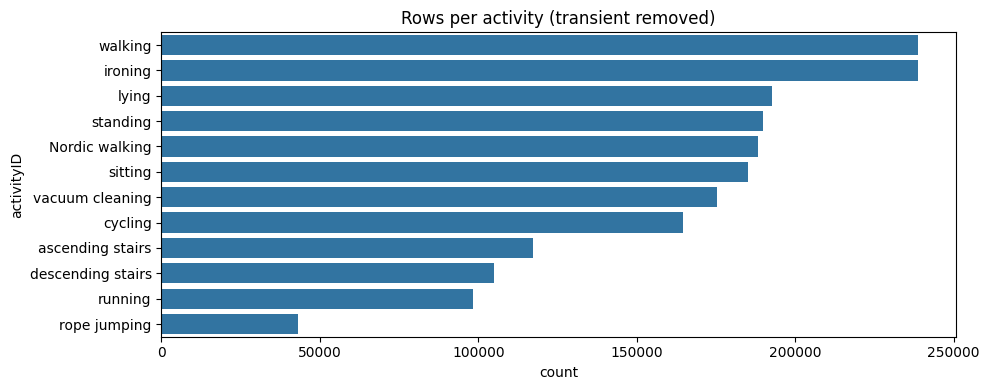

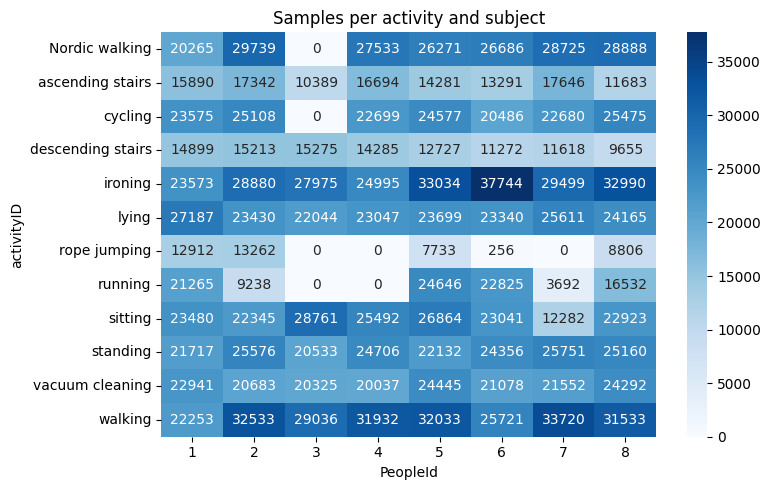

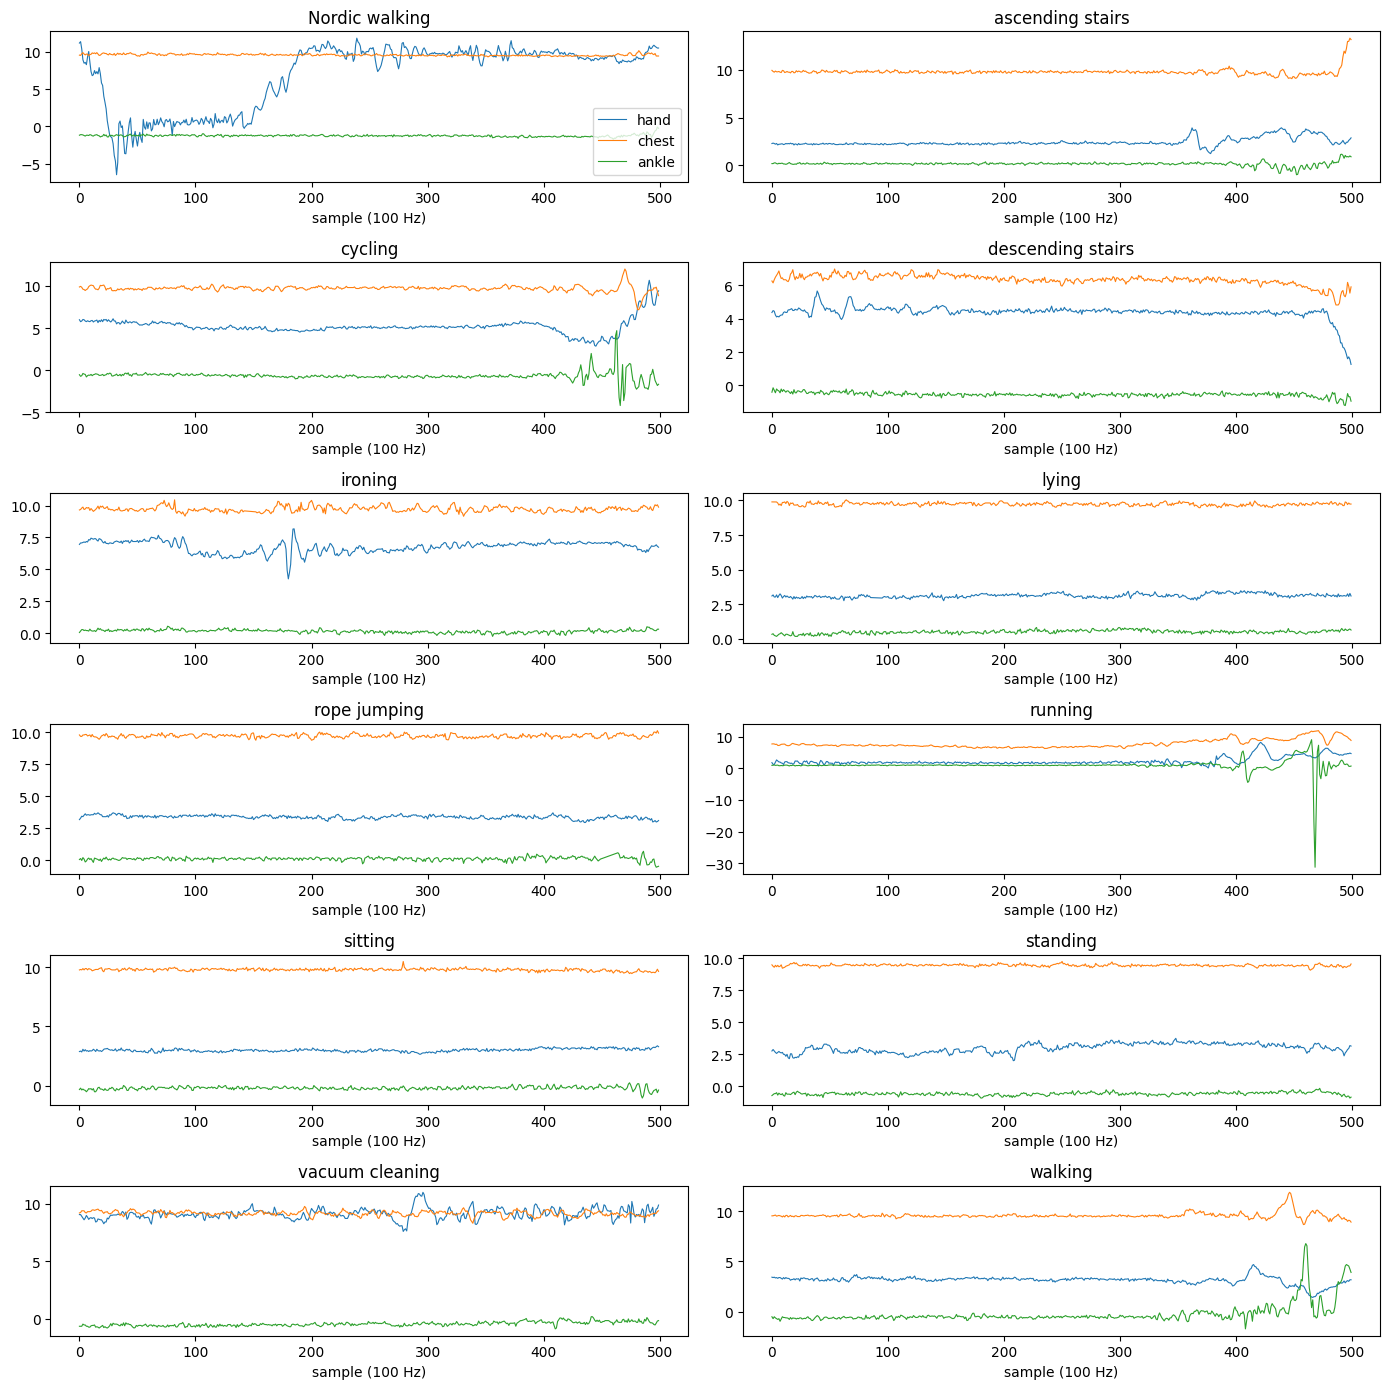

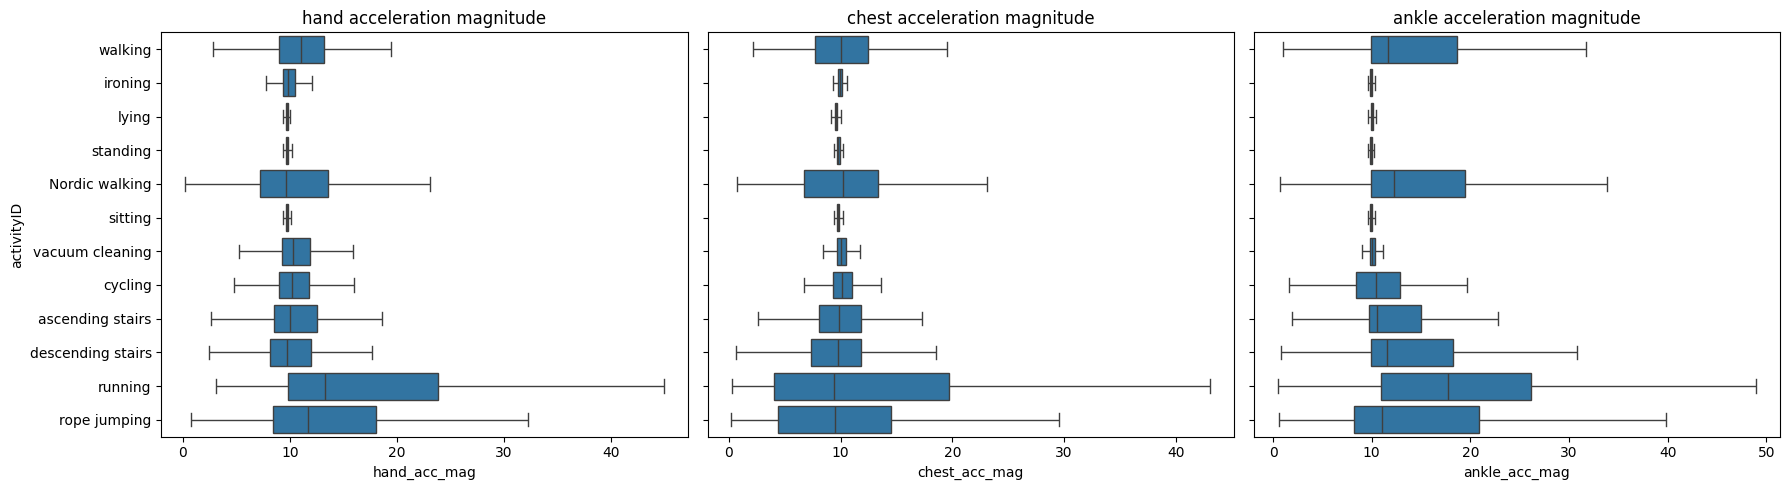

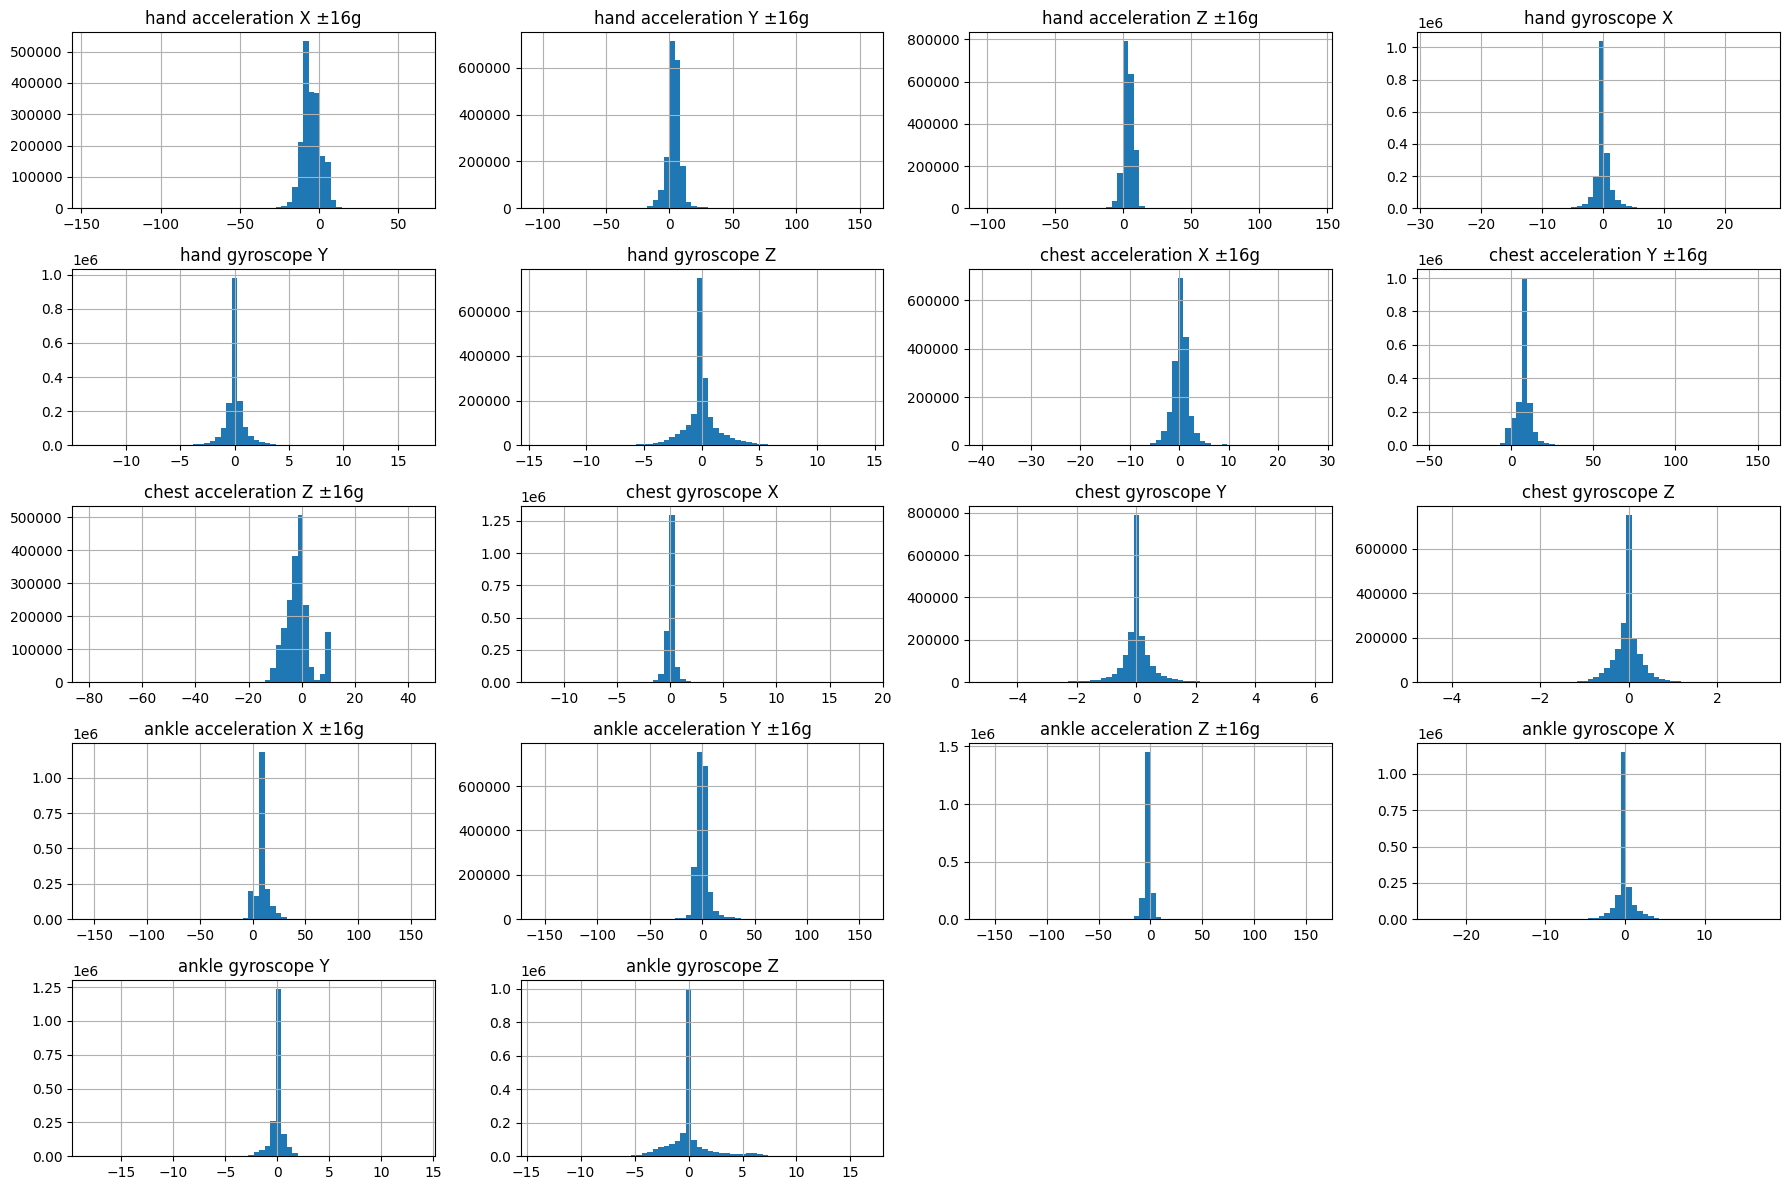


% of samples at sensor limit (|a| > 156 m/s²):
ankle acceleration X ±16g    0.001
hand acceleration X ±16g     0.000
hand acceleration Y ±16g     0.000
chest acceleration X ±16g    0.000
hand acceleration Z ±16g     0.000
chest acceleration Y ±16g    0.000
chest acceleration Z ±16g    0.000
ankle acceleration Y ±16g    0.000
ankle acceleration Z ±16g    0.000
dtype: float64
                           skew    kurt
hand acceleration X ±16g  -0.48    5.20
hand acceleration Y ±16g   2.46   44.70
hand acceleration Z ±16g  -0.73    9.35
hand gyroscope X           0.09   12.88
hand gyroscope Y           0.62   10.28
hand gyroscope Z          -0.18    5.90
chest acceleration X ±16g  0.30    7.22
chest acceleration Y ±16g  1.61   22.61
chest acceleration Z ±16g  0.35    1.70
chest gyroscope X          3.29   65.95
chest gyroscope Y          0.02    8.50
chest gyroscope Z         -0.04    6.35
ankle acceleration X ±16g  2.89   49.37
ankle acceleration Y ±16g  0.24   37.45
ankle acceleration Z ±

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# 4.0 Drop the 1-row segment (and any other tiny ones)
seg_len = df.groupby('segment')['segment'].transform('size')
df = df[seg_len >= 128].reset_index(drop=True)
print("Shape after dropping tiny segments:", df.shape)

# 4.1 Class distribution
order = df['activityID'].value_counts().index
plt.figure(figsize=(10,4))
sns.countplot(data=df, y='activityID', order=order)
plt.title("Rows per activity (transient removed)")
plt.tight_layout(); plt.show()

# 4.2 Activity x subject heatmap (shows who did what)
ct = pd.crosstab(df['activityID'], df['PeopleId'])
plt.figure(figsize=(8,5))
sns.heatmap(ct, annot=True, fmt='d', cmap='Blues')
plt.title("Samples per activity and subject")
plt.tight_layout(); plt.show()

# 4.3 Raw signal per activity: 5 seconds (500 samples) of chest, hand, ankle acc-Y
fig, axes = plt.subplots(6, 2, figsize=(14, 14), sharey=False)
for ax, act in zip(axes.ravel(), le.classes_):
    sub = df[(df['activityID'] == act) & (df['PeopleId'] == 5)].head(500)
    for col, name in [('hand acceleration Y ±16g','hand'),
                      ('chest acceleration Y ±16g','chest'),
                      ('ankle acceleration Y ±16g','ankle')]:
        ax.plot(sub[col].values, label=name, lw=0.8)
    ax.set_title(act); ax.set_xlabel("sample (100 Hz)")
axes[0,0].legend()
plt.tight_layout(); plt.show()

# 4.4 Acceleration magnitude per sensor by activity (a good univariate summary)
for s in ['hand', 'chest', 'ankle']:
    cols = [f'{s} acceleration {a} ±16g' for a in 'XYZ']
    df[f'{s}_acc_mag'] = np.sqrt((df[cols]**2).sum(axis=1))

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, s in zip(axes, ['hand', 'chest', 'ankle']):
    sns.boxplot(data=df.sample(200000, random_state=0), x=f'{s}_acc_mag',
                y='activityID', order=order, ax=ax, showfliers=False)
    ax.set_title(f"{s} acceleration magnitude")
plt.tight_layout(); plt.show()

# 4.5 Histograms of all 18 channels
df[imu_cols].hist(bins=60, figsize=(18, 12))
plt.tight_layout(); plt.show()

# 4.6 Saturation check: how often does each accelerometer channel hit the ±16g limit?
acc_cols = [c for c in imu_cols if 'acceleration' in c]
sat = (df[acc_cols].abs() > 156).mean() * 100
print("\n% of samples at sensor limit (|a| > 156 m/s²):")
print(sat.round(3).sort_values(ascending=False))

# 4.7 Skewness and kurtosis of the channels
print(df[imu_cols].agg(['skew', 'kurt']).T.round(2))

In [13]:
from scipy.signal import decimate
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

WIN, STEP = 128, 64          # 2.56 s at 50 Hz, 50% overlap
TRAIN_S, VAL_S, TEST_S = [1,2,3,4,6,7], [8], [5]

X_list, y_list, s_list = [], [], []
for seg_id, g in df.groupby('segment', sort=False):
    sig = g[imu_cols].values.astype(np.float64)
    # 100 Hz -> 50 Hz with anti-aliasing filter
    sig = decimate(sig, 2, axis=0, zero_phase=True).astype(np.float32)
    if len(sig) < WIN:
        continue
    label, subj = g['label'].iloc[0], g['PeopleId'].iloc[0]
    for start in range(0, len(sig) - WIN + 1, STEP):
        X_list.append(sig[start:start+WIN])
        y_list.append(label)
        s_list.append(subj)

X = np.stack(X_list); y = np.array(y_list); subj = np.array(s_list)
print("All windows:", X.shape, "(windows, time steps, channels)")

# Subject-wise split
tr, va, te = np.isin(subj, TRAIN_S), np.isin(subj, VAL_S), np.isin(subj, TEST_S)
X_train, y_train = X[tr], y[tr]
X_val,   y_val   = X[va], y[va]
X_test,  y_test  = X[te], y[te]
print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)

# Standardize per channel, fit on TRAIN only
scaler = StandardScaler().fit(X_train.reshape(-1, X_train.shape[-1]))
def scale(a):
    return scaler.transform(a.reshape(-1, a.shape[-1])).reshape(a.shape).astype(np.float32)
X_train, X_val, X_test = scale(X_train), scale(X_val), scale(X_test)

# Class distribution per split
names = le.classes_
dist = pd.DataFrame({
    'train': np.bincount(y_train, minlength=12),
    'val':   np.bincount(y_val,   minlength=12),
    'test':  np.bincount(y_test,  minlength=12)}, index=names)
print(dist)

# Class weights for imbalance
cw = compute_class_weight('balanced', classes=np.arange(12), y=y_train)
class_weight = dict(enumerate(cw))
print({names[k]: round(v, 2) for k, v in class_weight.items()})

# Save so you don't redo this after a Colab restart
np.savez_compressed('/content/pamap2_windows.npz',
    X_train=X_train, y_train=y_train, X_val=X_val, y_val=y_val,
    X_test=X_test, y_test=y_test, classes=names)

All windows: (14975, 128, 18) (windows, time steps, channels)
Train: (10841, 128, 18) Val: (2027, 128, 18) Test: (2107, 128, 18)
                   train  val  test
Nordic walking      1032  224   204
ascending stairs     695   89   108
cycling              889  198   191
descending stairs    626   72    96
ironing             1340  256   257
lying               1123  187   184
rope jumping         202   67    59
running              440  128   191
sitting             1049  178   208
standing            1106  195   171
vacuum cleaning      980  188   189
walking             1359  245   249
{'Nordic walking': np.float64(0.88), 'ascending stairs': np.float64(1.3), 'cycling': np.float64(1.02), 'descending stairs': np.float64(1.44), 'ironing': np.float64(0.67), 'lying': np.float64(0.8), 'rope jumping': np.float64(4.47), 'running': np.float64(2.05), 'sitting': np.float64(0.86), 'standing': np.float64(0.82), 'vacuum cleaning': np.float64(0.92), 'walking': np.float64(0.66)}


['hand acceleration X ±16g', 'hand acceleration Y ±16g', 'hand acceleration Z ±16g'] ['chest acceleration X ±16g', 'chest acceleration Y ±16g', 'chest acceleration Z ±16g'] ['ankle acceleration X ±16g', 'ankle acceleration Y ±16g', 'ankle acceleration Z ±16g']
Feature matrix: (10841, 222)

Random Forest  (trained in 46s)
  val : acc=0.905  macro-F1=0.902
  test: acc=0.905  macro-F1=0.906

SVM (RBF)  (trained in 8s)
  val : acc=0.612  macro-F1=0.490
  test: acc=0.864  macro-F1=0.858

=== Random Forest: per-class report (test) ===
                   precision    recall  f1-score   support

   Nordic walking      0.990     0.980     0.985       204
 ascending stairs      0.868     0.917     0.892       108
          cycling      0.973     0.937     0.955       191
descending stairs      0.963     0.812     0.881        96
          ironing      0.832     0.946     0.885       257
            lying      0.966     0.935     0.950       184
     rope jumping      1.000     0.932     0.965   

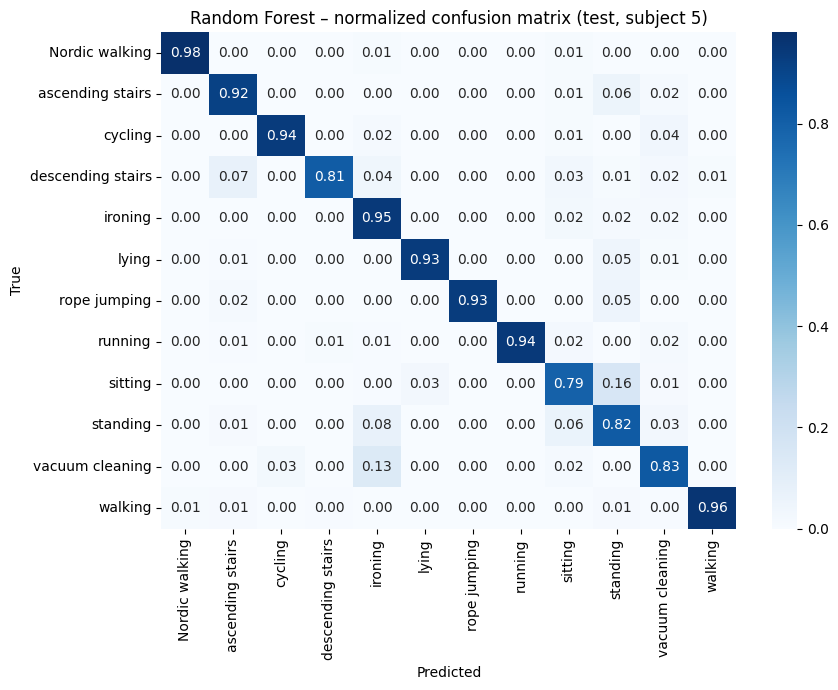

In [14]:
from scipy.stats import skew, kurtosis
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, f1_score,
                             classification_report, confusion_matrix)
import time

FS = 50  # Hz after downsampling

def extract_features(W):
    """W: (n_windows, 128, 18) -> (n_windows, n_features)"""
    f = []
    f += [W.mean(1), W.std(1), W.min(1), W.max(1), np.median(W, 1)]
    f += [np.percentile(W, 75, axis=1) - np.percentile(W, 25, axis=1)]   # IQR
    f += [(W**2).mean(1)]                                                # energy
    f += [skew(W, axis=1), kurtosis(W, axis=1)]
    zc = (np.diff(np.signbit(W - W.mean(1, keepdims=True)), axis=1) != 0).mean(1)
    f += [zc]                                                            # zero-crossing rate
    # Frequency domain
    mag = np.abs(np.fft.rfft(W - W.mean(1, keepdims=True), axis=1))
    freqs = np.fft.rfftfreq(W.shape[1], 1/FS)
    f += [freqs[mag.argmax(1)]]                                          # dominant frequency
    f += [(mag**2).sum(1) / W.shape[1]]                                  # spectral energy
    # Acceleration magnitude per sensor (hand 0-2, chest 6-8, ankle 12-14 in imu_cols order)
    for idx in [(0,1,2), (6,7,8), (12,13,14)]:
        m = np.sqrt((W[:, :, list(idx)]**2).sum(2))
        f += [m.mean(1, keepdims=True), m.std(1, keepdims=True)]
    return np.nan_to_num(np.concatenate(f, axis=1))

print(imu_cols[:3], imu_cols[6:9], imu_cols[12:15])   # verify the column groups
Ftr, Fva, Fte = map(extract_features, (X_train, X_val, X_test))
print("Feature matrix:", Ftr.shape)

def evaluate(name, model):
    t = time.time()
    model.fit(Ftr, y_train)
    out = {}
    for split, F, y_true in [('val', Fva, y_val), ('test', Fte, y_test)]:
        p = model.predict(F)
        out[split] = (accuracy_score(y_true, p), f1_score(y_true, p, average='macro'), p)
    print(f"\n{name}  (trained in {time.time()-t:.0f}s)")
    print(f"  val : acc={out['val'][0]:.3f}  macro-F1={out['val'][1]:.3f}")
    print(f"  test: acc={out['test'][0]:.3f}  macro-F1={out['test'][1]:.3f}")
    return out

rf  = RandomForestClassifier(n_estimators=300, class_weight='balanced',
                             n_jobs=-1, random_state=42)
svm = make_pipeline(StandardScaler(),
                    SVC(kernel='rbf', C=10, gamma='scale', class_weight='balanced'))

res_rf  = evaluate("Random Forest", rf)
res_svm = evaluate("SVM (RBF)", svm)

# Detailed look at the better model on the test set
best_name, best = ("Random Forest", res_rf) if res_rf['test'][1] >= res_svm['test'][1] else ("SVM", res_svm)
print(f"\n=== {best_name}: per-class report (test) ===")
print(classification_report(y_test, best['test'][2], target_names=names, digits=3))

import seaborn as sns, matplotlib.pyplot as plt
cm = confusion_matrix(y_test, best['test'][2], normalize='true')
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', xticklabels=names, yticklabels=names)
plt.title(f"{best_name} – normalized confusion matrix (test, subject 5)")
plt.xlabel("Predicted"); plt.ylabel("True")
plt.tight_layout(); plt.show()

In [15]:
pv = svm.predict(Fva)
print(classification_report(y_val, pv, target_names=names, digits=3))

                   precision    recall  f1-score   support

   Nordic walking      0.000     0.000     0.000       224
 ascending stairs      0.462     0.809     0.588        89
          cycling      0.916     0.939     0.928       198
descending stairs      0.313     0.875     0.462        72
          ironing      0.870     0.574     0.692       256
            lying      0.475     0.979     0.640       187
     rope jumping      1.000     0.015     0.029        67
          running      0.000     0.000     0.000       128
          sitting      0.780     0.180     0.292       178
         standing      0.442     0.846     0.581       195
  vacuum cleaning      0.664     0.851     0.746       188
          walking      0.899     0.943     0.920       245

         accuracy                          0.612      2027
        macro avg      0.568     0.584     0.490      2027
     weighted avg      0.589     0.612     0.542      2027



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Model: "cnn1d"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 18)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 128, 64)        │         5,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 128, 64)        │        20,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 64, 128)        │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 64, 128)        │        49,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 64, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 32, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 12)             │         1,548 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 136,332 (532.55 KB)

 Trainable params: 135,564 (529.55 KB)

 Non-trainable params: 768 (3.00 KB)

Epoch 1/60
170/170 - 29s - 173ms/step - accuracy: 0.8110 - loss: 0.7049 - val_accuracy: 0.3049 - val_loss: 2.8530 - learning_rate: 0.0010
Epoch 2/60
170/170 - 18s - 104ms/step - accuracy: 0.9098 - loss: 0.3426 - val_accuracy: 0.3177 - val_loss: 4.0289 - learning_rate: 0.0010
Epoch 3/60
170/170 - 1s - 5ms/step - accuracy: 0.9217 - loss: 0.2893 - val_accuracy: 0.3310 - val_loss: 3.5776 - learning_rate: 0.0010
Epoch 4/60
170/170 - 1s - 5ms/step - accuracy: 0.9290 - loss: 0.2565 - val_accuracy: 0.2669 - val_loss: 3.8563 - learning_rate: 0.0010
Epoch 5/60
170/170 - 1s - 5ms/step - accuracy: 0.9352 - loss: 0.2428 - val_accuracy: 0.2758 - val_loss: 4.3356 - learning_rate: 0.0010
Epoch 6/60
170/170 - 1s - 5ms/step - accuracy: 0.9451 - loss: 0.1969 - val_accuracy: 0.2580 - val_loss: 4.2220 - learning_rate: 5.0000e-04
Epoch 7/60
170/170 - 1s - 5ms/step - accuracy: 0.9495 - loss: 0.1825 - val_accuracy: 0.2713 - val_loss: 4.2745 - learning_rate: 5.0000e-04
Epoch 8/60
170/170 - 1s - 5ms/step - accu

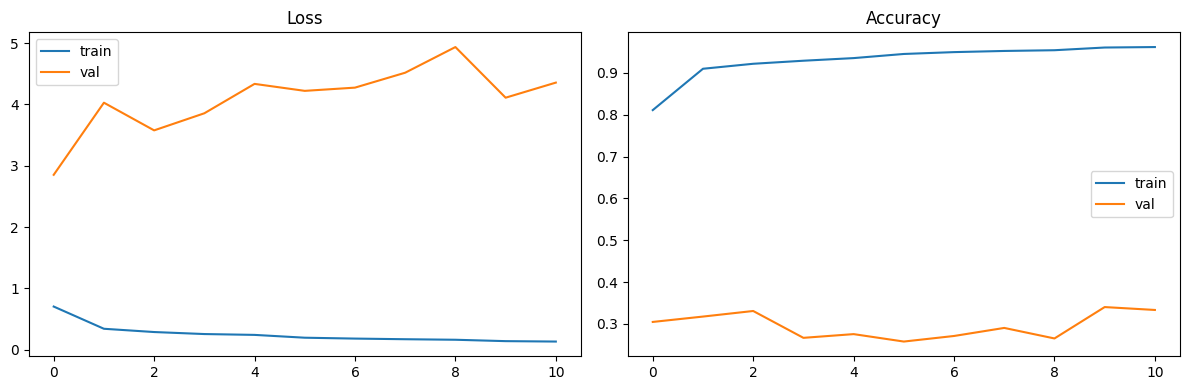

1D-CNN val: acc=0.305  macro-F1=0.216
1D-CNN test: acc=0.829  macro-F1=0.835
                   precision    recall  f1-score   support

   Nordic walking      0.900     0.975     0.936       204
 ascending stairs      0.876     0.917     0.896       108
          cycling      0.865     0.838     0.851       191
descending stairs      0.768     0.792     0.779        96
          ironing      0.847     0.732     0.785       257
            lying      0.901     0.935     0.917       184
     rope jumping      0.982     0.932     0.957        59
          running      1.000     0.906     0.951       191
          sitting      0.650     0.635     0.642       208
         standing      0.626     0.713     0.667       171
  vacuum cleaning      0.694     0.709     0.702       189
          walking      0.926     0.952     0.939       249

         accuracy                          0.829      2107
        macro avg      0.836     0.836     0.835      2107
     weighted avg      0.832     0.8

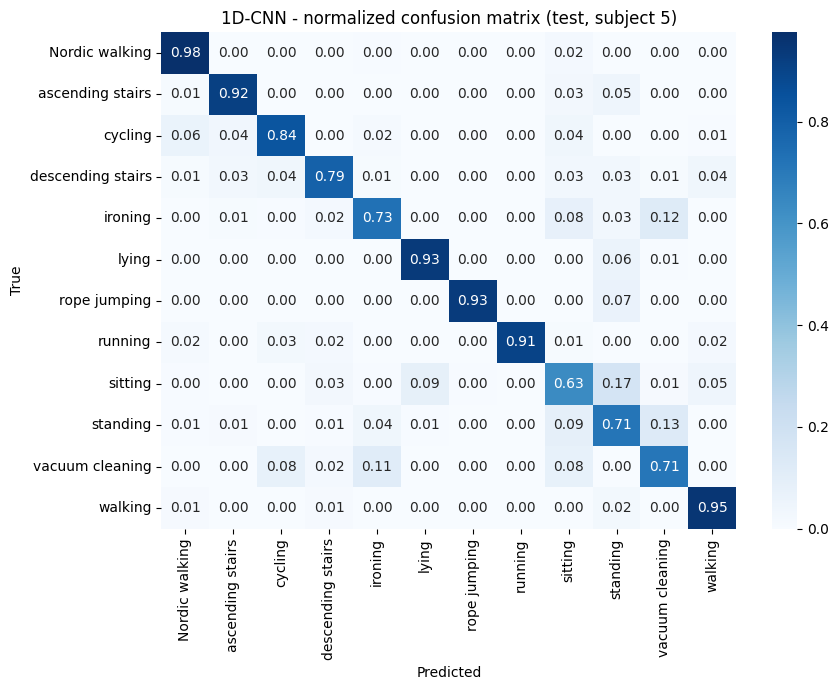

In [16]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(42)

def build_cnn(input_shape=(128, 18), n_classes=12):
    inp = layers.Input(shape=input_shape)
    x = inp
    for filters, k in [(64, 5), (64, 5)]:
        x = layers.Conv1D(filters, k, padding='same')(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Dropout(0.3)(x)

    for filters, k in [(128, 5), (128, 3)]:
        x = layers.Conv1D(filters, k, padding='same')(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Dropout(0.3)(x)

    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(n_classes, activation='softmax')(x)
    return keras.Model(inp, out, name="cnn1d")

cnn = build_cnn()
cnn.summary()

cnn.compile(optimizer=keras.optimizers.Adam(1e-3),
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy'])

callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=10,
                                  restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4)
]

hist = cnn.fit(X_train, y_train,
               validation_data=(X_val, y_val),
               epochs=60, batch_size=64,
               class_weight=class_weight,
               callbacks=callbacks, verbose=2)

# Training curves
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist.history['loss'], label='train'); ax[0].plot(hist.history['val_loss'], label='val')
ax[0].set_title('Loss'); ax[0].legend()
ax[1].plot(hist.history['accuracy'], label='train'); ax[1].plot(hist.history['val_accuracy'], label='val')
ax[1].set_title('Accuracy'); ax[1].legend()
plt.tight_layout(); plt.show()

# Evaluation
def report(model, name):
    for split, X_, y_ in [('val', X_val, y_val), ('test', X_test, y_test)]:
        p = model.predict(X_, verbose=0).argmax(1)
        print(f"{name} {split}: acc={accuracy_score(y_, p):.3f}  macro-F1={f1_score(y_, p, average='macro'):.3f}")
    p = model.predict(X_test, verbose=0).argmax(1)
    print(classification_report(y_test, p, target_names=names, digits=3))
    cm = confusion_matrix(y_test, p, normalize='true')
    plt.figure(figsize=(9, 7))
    sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', xticklabels=names, yticklabels=names)
    plt.title(f"{name} - normalized confusion matrix (test, subject 5)")
    plt.xlabel("Predicted"); plt.ylabel("True"); plt.tight_layout(); plt.show()
    return p

pred_cnn = report(cnn, "1D-CNN")
cnn.save('/content/cnn1d.keras')

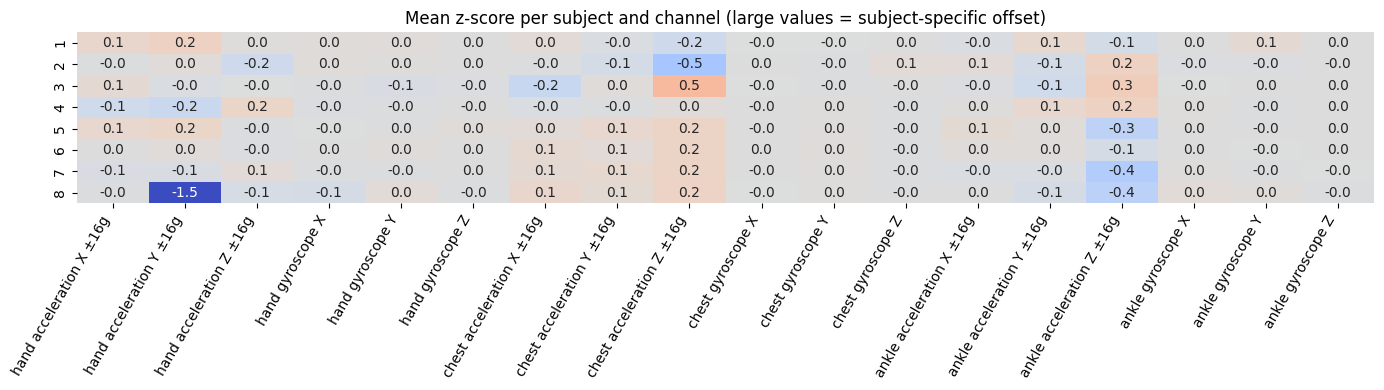

                   precision    recall  f1-score   support

   Nordic walking      0.000     0.000     0.000       224
 ascending stairs      0.000     0.000     0.000        89
          cycling      0.385     0.859     0.531       198
descending stairs      0.078     0.875     0.144        72
          ironing      0.409     0.070     0.120       256
            lying      0.756     0.947     0.841       187
     rope jumping      0.000     0.000     0.000        67
          running      0.000     0.000     0.000       128
          sitting      0.000     0.000     0.000       178
         standing      0.576     0.446     0.503       195
  vacuum cleaning      0.381     0.543     0.447       188
          walking      0.013     0.004     0.006       245

         accuracy                          0.305      2027
        macro avg      0.217     0.312     0.216      2027
     weighted avg      0.254     0.305     0.240      2027



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [17]:
# 1) Per-subject mean of each channel, in standardized units (fit on all train subjects)
sc_all = StandardScaler().fit(X[np.isin(subj, TRAIN_S)].reshape(-1, 18))
Xs = sc_all.transform(X.reshape(-1, 18)).reshape(X.shape)

subs = sorted(np.unique(subj))
means = pd.DataFrame({s: Xs[subj == s].mean(axis=(0, 1)) for s in subs}, index=imu_cols).T
plt.figure(figsize=(14, 4))
sns.heatmap(means, cmap='coolwarm', center=0, annot=True, fmt='.1f', cbar=False)
plt.title("Mean z-score per subject and channel (large values = subject-specific offset)")
plt.xticks(rotation=60, ha='right'); plt.tight_layout(); plt.show()

# 2) Which classes fail on subject 8?
pv = cnn.predict(X_val, verbose=0).argmax(1)
print(classification_report(y_val, pv, target_names=names, digits=3))

(10936, 128, 18) (1932, 128, 18) (2107, 128, 18)
Epoch 1/60
171/171 - 30s - 176ms/step - accuracy: 0.7874 - loss: 0.7830 - val_accuracy: 0.8276 - val_loss: 0.8101 - learning_rate: 0.0010
Epoch 2/60
171/171 - 1s - 5ms/step - accuracy: 0.9117 - loss: 0.3551 - val_accuracy: 0.8069 - val_loss: 0.9802 - learning_rate: 0.0010
Epoch 3/60
171/171 - 1s - 5ms/step - accuracy: 0.9247 - loss: 0.2978 - val_accuracy: 0.7816 - val_loss: 1.0330 - learning_rate: 0.0010
Epoch 4/60
171/171 - 1s - 5ms/step - accuracy: 0.9331 - loss: 0.2599 - val_accuracy: 0.7867 - val_loss: 1.0984 - learning_rate: 0.0010
Epoch 5/60
171/171 - 1s - 6ms/step - accuracy: 0.9354 - loss: 0.2368 - val_accuracy: 0.7847 - val_loss: 1.5168 - learning_rate: 0.0010
Epoch 6/60
171/171 - 1s - 5ms/step - accuracy: 0.9490 - loss: 0.1914 - val_accuracy: 0.7893 - val_loss: 1.5980 - learning_rate: 5.0000e-04
Epoch 7/60
171/171 - 1s - 5ms/step - accuracy: 0.9515 - loss: 0.1757 - val_accuracy: 0.7945 - val_loss: 1.4554 - learning_rate: 5.0000

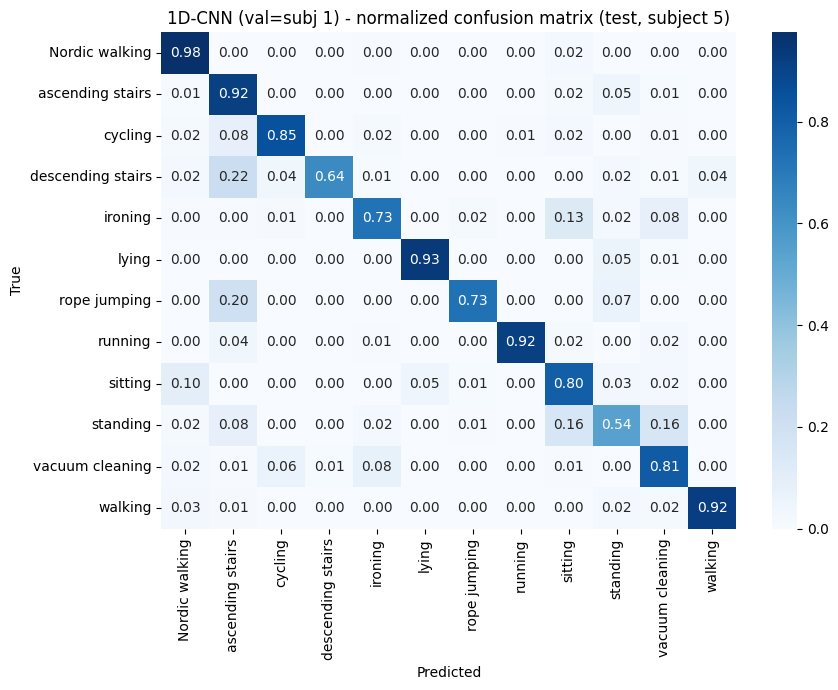

In [18]:
def make_split(train_s, val_s, test_s):
    tr, va, te = [np.isin(subj, s) for s in (train_s, val_s, test_s)]
    sc = StandardScaler().fit(X[tr].reshape(-1, 18))
    f = lambda a: sc.transform(a.reshape(-1, 18)).reshape(a.shape).astype(np.float32)
    return f(X[tr]), y[tr], f(X[va]), y[va], f(X[te]), y[te]

X_train, y_train, X_val, y_val, X_test, y_test = make_split([2,3,4,6,7,8], [1], [5])
cw = compute_class_weight('balanced', classes=np.arange(12), y=y_train)
class_weight = dict(enumerate(cw))
print(X_train.shape, X_val.shape, X_test.shape)

tf.keras.utils.set_random_seed(42)
cnn = build_cnn()
cnn.compile(optimizer=keras.optimizers.Adam(1e-3),
            loss='sparse_categorical_crossentropy', metrics=['accuracy'])

callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4)
]
hist = cnn.fit(X_train, y_train, validation_data=(X_val, y_val),
               epochs=60, batch_size=64, class_weight=class_weight,
               callbacks=callbacks, verbose=2)

pred_cnn = report(cnn, "1D-CNN (val=subj 1)")

In [19]:
Ftr, Fva, Fte = map(extract_features, (X_train, X_val, X_test))
res_rf = evaluate("Random Forest (new split)", rf)


Random Forest (new split)  (trained in 49s)
  val : acc=0.868  macro-F1=0.875
  test: acc=0.899  macro-F1=0.901


Epoch 1/80
171/171 - 28s - 165ms/step - accuracy: 0.6663 - loss: 1.1912 - val_accuracy: 0.7417 - val_loss: 1.0168 - learning_rate: 5.0000e-04
Epoch 2/80
171/171 - 1s - 7ms/step - accuracy: 0.8862 - loss: 0.4921 - val_accuracy: 0.8188 - val_loss: 0.9623 - learning_rate: 5.0000e-04
Epoch 3/80
171/171 - 1s - 6ms/step - accuracy: 0.9121 - loss: 0.3944 - val_accuracy: 0.8163 - val_loss: 0.9449 - learning_rate: 5.0000e-04
Epoch 4/80
171/171 - 1s - 6ms/step - accuracy: 0.9194 - loss: 0.3492 - val_accuracy: 0.8028 - val_loss: 1.0732 - learning_rate: 5.0000e-04
Epoch 5/80
171/171 - 1s - 6ms/step - accuracy: 0.9249 - loss: 0.3246 - val_accuracy: 0.7883 - val_loss: 1.1062 - learning_rate: 5.0000e-04
Epoch 6/80
171/171 - 1s - 6ms/step - accuracy: 0.9328 - loss: 0.3001 - val_accuracy: 0.8276 - val_loss: 1.1200 - learning_rate: 5.0000e-04
Epoch 7/80
171/171 - 1s - 6ms/step - accuracy: 0.9347 - loss: 0.2921 - val_accuracy: 0.8225 - val_loss: 1.2223 - learning_rate: 5.0000e-04
Epoch 8/80
171/171 - 1s 

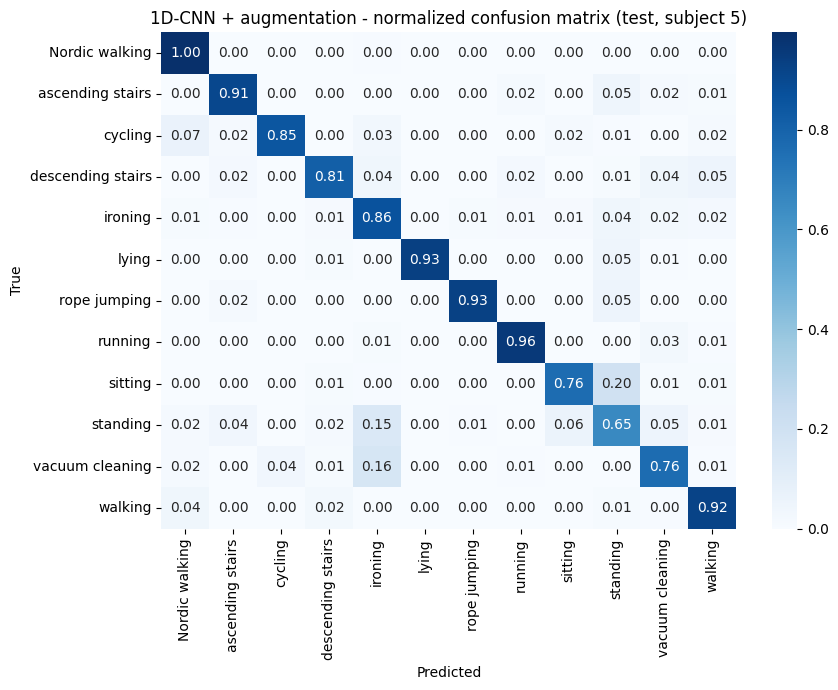

In [20]:
class RandomScale(layers.Layer):
    """Multiply each channel by a random factor ~ N(1, sigma). Training only."""
    def __init__(self, sigma=0.15, **kw):
        super().__init__(**kw); self.sigma = sigma
    def call(self, x, training=None):
        if training:
            s = tf.random.normal((tf.shape(x)[0], 1, tf.shape(x)[2]), 1.0, self.sigma)
            return x * s
        return x
    def get_config(self):
        return {**super().get_config(), "sigma": self.sigma}

reg = keras.regularizers.l2(1e-4)

def build_cnn_aug(input_shape=(128, 18), n_classes=12):
    inp = layers.Input(shape=input_shape)
    x = RandomScale(0.15)(inp)
    x = layers.GaussianNoise(0.1)(x)
    for filters, k in [(64, 5), (64, 5)]:
        x = layers.Conv1D(filters, k, padding='same', kernel_regularizer=reg)(x)
        x = layers.BatchNormalization()(x); x = layers.Activation('relu')(x)
    x = layers.MaxPooling1D(2)(x); x = layers.Dropout(0.4)(x)
    for filters, k in [(128, 5), (128, 3)]:
        x = layers.Conv1D(filters, k, padding='same', kernel_regularizer=reg)(x)
        x = layers.BatchNormalization()(x); x = layers.Activation('relu')(x)
    x = layers.MaxPooling1D(2)(x); x = layers.Dropout(0.4)(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(128, activation='relu', kernel_regularizer=reg)(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(n_classes, activation='softmax')(x)
    return keras.Model(inp, out, name="cnn1d_aug")

tf.keras.utils.set_random_seed(42)
cnn_aug = build_cnn_aug()
cnn_aug.compile(optimizer=keras.optimizers.Adam(5e-4),
                loss='sparse_categorical_crossentropy', metrics=['accuracy'])

callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_accuracy', mode='max', patience=15,
                                  restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_accuracy', mode='max',
                                      factor=0.5, patience=5)
]
hist = cnn_aug.fit(X_train, y_train, validation_data=(X_val, y_val),
                   epochs=80, batch_size=64, class_weight=class_weight,
                   callbacks=callbacks, verbose=2)

pred_cnn_aug = report(cnn_aug, "1D-CNN + augmentation")

Model: "lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 128, 18)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_scale_1 (RandomScale)    │ (None, 128, 18)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gaussian_noise_1                │ (None, 128, 18)        │             0 │
│ (GaussianNoise)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128, 64)        │        21,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 12)             │           780 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,212 (231.30 KB)

 Trainable params: 59,212 (231.30 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/80
171/171 - 16s - 96ms/step - accuracy: 0.4897 - loss: 1.6107 - val_accuracy: 0.7417 - val_loss: 1.0585 - learning_rate: 0.0010
Epoch 2/80
171/171 - 12s - 68ms/step - accuracy: 0.8264 - loss: 0.7431 - val_accuracy: 0.7660 - val_loss: 1.1510 - learning_rate: 0.0010
Epoch 3/80
171/171 - 3s - 15ms/step - accuracy: 0.8694 - loss: 0.6011 - val_accuracy: 0.7552 - val_loss: 1.1575 - learning_rate: 0.0010
Epoch 4/80
171/171 - 3s - 18ms/step - accuracy: 0.8877 - loss: 0.5289 - val_accuracy: 0.7780 - val_loss: 1.1028 - learning_rate: 0.0010
Epoch 5/80
171/171 - 3s - 15ms/step - accuracy: 0.9019 - loss: 0.4728 - val_accuracy: 0.7723 - val_loss: 1.1661 - learning_rate: 0.0010
Epoch 6/80
171/171 - 3s - 15ms/step - accuracy: 0.9072 - loss: 0.4468 - val_accuracy: 0.7987 - val_loss: 1.0312 - learning_rate: 0.0010
Epoch 7/80
171/171 - 3s - 15ms/step - accuracy: 0.9121 - loss: 0.4279 - val_accuracy: 0.7914 - val_loss: 1.1158 - learning_rate: 0.0010
Epoch 8/80
171/171 - 3s - 15ms/step - accuracy

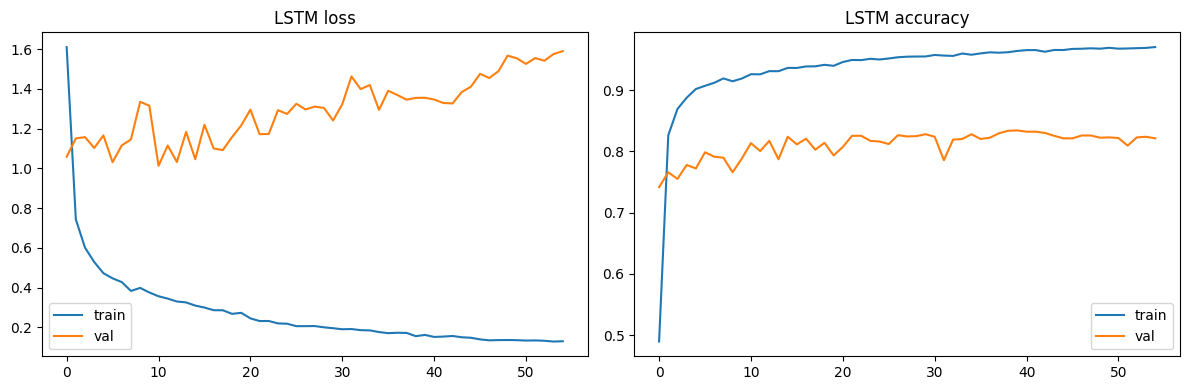

LSTM val: acc=0.834  macro-F1=0.842
LSTM test: acc=0.813  macro-F1=0.797
                   precision    recall  f1-score   support

   Nordic walking      0.980     0.980     0.980       204
 ascending stairs      0.784     0.907     0.841       108
          cycling      0.913     0.880     0.896       191
descending stairs      0.380     0.760     0.507        96
          ironing      0.810     0.860     0.834       257
            lying      0.910     0.935     0.922       184
     rope jumping      0.810     0.864     0.836        59
          running      0.974     0.387     0.554       191
          sitting      0.849     0.760     0.802       208
         standing      0.663     0.690     0.676       171
  vacuum cleaning      0.732     0.751     0.742       189
          walking      0.979     0.956     0.967       249

         accuracy                          0.813      2107
        macro avg      0.815     0.811     0.797      2107
     weighted avg      0.843     0.813  

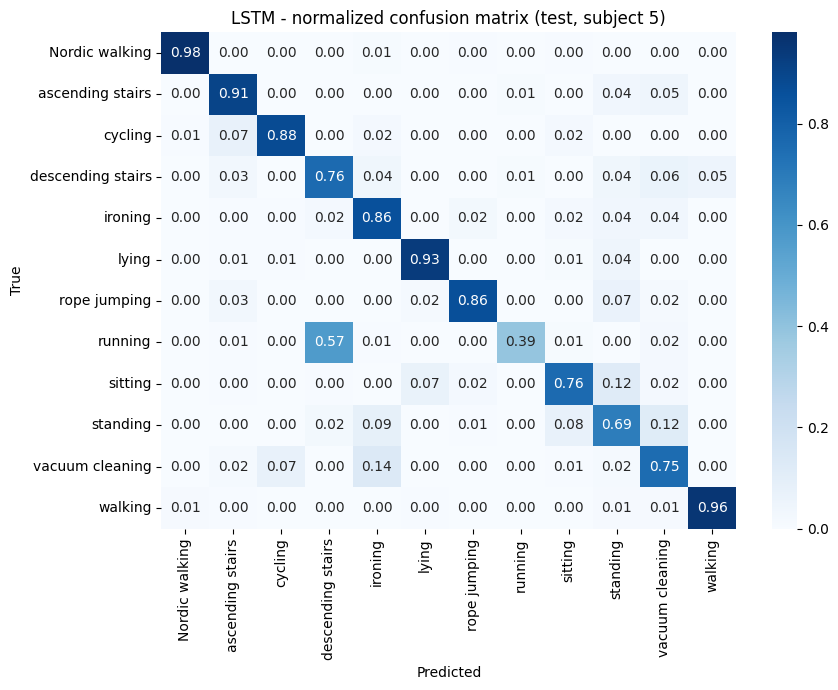

                       Test accuracy  Test macro-F1
Random Forest                  0.899          0.901
1D-CNN + augmentation          0.863          0.865
LSTM                           0.813          0.797


In [21]:
def build_lstm(input_shape=(128, 18), n_classes=12):
    inp = layers.Input(shape=input_shape)
    x = RandomScale(0.15)(inp)
    x = layers.GaussianNoise(0.1)(x)
    x = layers.LSTM(64, return_sequences=True)(x)
    x = layers.Dropout(0.4)(x)
    x = layers.LSTM(64)(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(64, activation='relu', kernel_regularizer=reg)(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(n_classes, activation='softmax')(x)
    return keras.Model(inp, out, name="lstm")

tf.keras.utils.set_random_seed(42)
lstm = build_lstm()
lstm.summary()
lstm.compile(optimizer=keras.optimizers.Adam(1e-3, clipnorm=1.0),
             loss='sparse_categorical_crossentropy', metrics=['accuracy'])

callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_accuracy', mode='max', patience=15,
                                  restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_accuracy', mode='max',
                                      factor=0.5, patience=5)
]
hist_lstm = lstm.fit(X_train, y_train, validation_data=(X_val, y_val),
                     epochs=80, batch_size=64, class_weight=class_weight,
                     callbacks=callbacks, verbose=2)

# Training curves
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist_lstm.history['loss'], label='train'); ax[0].plot(hist_lstm.history['val_loss'], label='val')
ax[0].set_title('LSTM loss'); ax[0].legend()
ax[1].plot(hist_lstm.history['accuracy'], label='train'); ax[1].plot(hist_lstm.history['val_accuracy'], label='val')
ax[1].set_title('LSTM accuracy'); ax[1].legend()
plt.tight_layout(); plt.show()

pred_lstm = report(lstm, "LSTM")
lstm.save('/content/lstm.keras')

# Comparison table (all on the same split: val = subject 1, test = subject 5)
rows = {
    "Random Forest":        res_rf['test'][2],
    "1D-CNN + augmentation": pred_cnn_aug,
    "LSTM":                 pred_lstm,
}
cmp_df = pd.DataFrame({
    k: {"Test accuracy": accuracy_score(y_test, p),
        "Test macro-F1": f1_score(y_test, p, average='macro')}
    for k, p in rows.items()}).T.round(3)
print(cmp_df)

Model: "cnn_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 128, 18)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_scale_2 (RandomScale)    │ (None, 128, 18)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gaussian_noise_2                │ (None, 128, 18)        │             0 │
│ (GaussianNoise)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_12 (Conv1D)              │ (None, 128, 64)        │         5,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 128, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_12 (Activation)      │ (None, 128, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_6 (MaxPooling1D)  │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_13 (Conv1D)              │ (None, 64, 128)        │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 64, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_13 (Activation)      │ (None, 64, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_7 (MaxPooling1D)  │ (None, 32, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 32, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 12)             │           780 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,028 (398.55 KB)

 Trainable params: 101,644 (397.05 KB)

 Non-trainable params: 384 (1.50 KB)

Epoch 1/80
171/171 - 12s - 71ms/step - accuracy: 0.4919 - loss: 1.6827 - val_accuracy: 0.7490 - val_loss: 1.0216 - learning_rate: 5.0000e-04
Epoch 2/80
171/171 - 4s - 23ms/step - accuracy: 0.8014 - loss: 0.7893 - val_accuracy: 0.7935 - val_loss: 0.8629 - learning_rate: 5.0000e-04
Epoch 3/80
171/171 - 3s - 19ms/step - accuracy: 0.8630 - loss: 0.5879 - val_accuracy: 0.7759 - val_loss: 0.9637 - learning_rate: 5.0000e-04
Epoch 4/80
171/171 - 2s - 13ms/step - accuracy: 0.8888 - loss: 0.4948 - val_accuracy: 0.7702 - val_loss: 0.9922 - learning_rate: 5.0000e-04
Epoch 5/80
171/171 - 2s - 12ms/step - accuracy: 0.9026 - loss: 0.4424 - val_accuracy: 0.8054 - val_loss: 0.9268 - learning_rate: 5.0000e-04
Epoch 6/80
171/171 - 2s - 12ms/step - accuracy: 0.9100 - loss: 0.4027 - val_accuracy: 0.8209 - val_loss: 1.0069 - learning_rate: 5.0000e-04
Epoch 7/80
171/171 - 2s - 12ms/step - accuracy: 0.9181 - loss: 0.3678 - val_accuracy: 0.7717 - val_loss: 1.0920 - learning_rate: 5.0000e-04
Epoch 8/80
171/171 

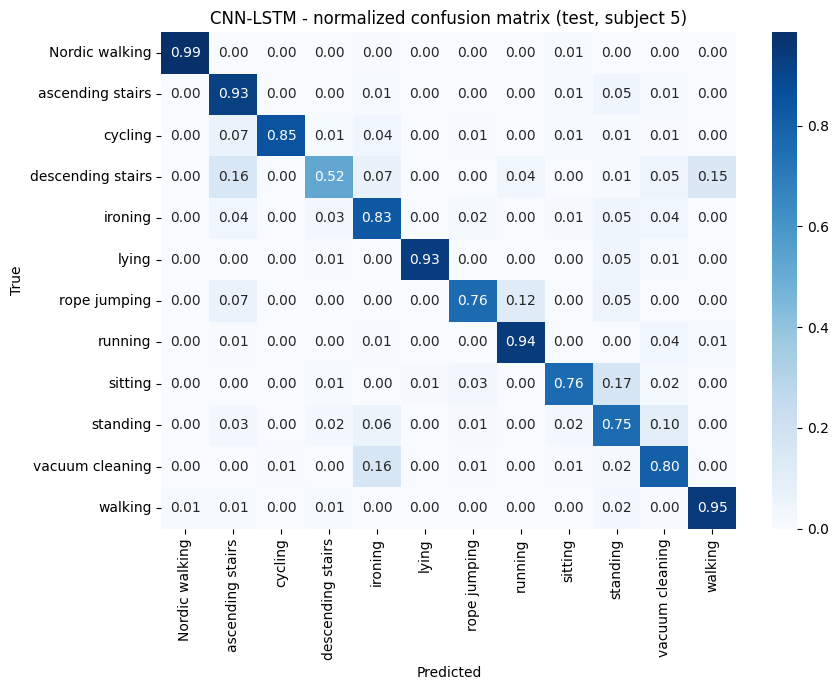

                       Test accuracy  Test macro-F1
Random Forest                  0.899          0.901
1D-CNN + augmentation          0.863          0.865
LSTM                           0.813          0.797
CNN-LSTM                       0.854          0.834


In [22]:
def build_cnn_lstm(input_shape=(128, 18), n_classes=12):
    inp = layers.Input(shape=input_shape)
    x = RandomScale(0.15)(inp)
    x = layers.GaussianNoise(0.1)(x)

    x = layers.Conv1D(64, 5, padding='same', kernel_regularizer=reg)(x)
    x = layers.BatchNormalization()(x); x = layers.Activation('relu')(x)
    x = layers.MaxPooling1D(2)(x)                       # 128 -> 64

    x = layers.Conv1D(128, 5, padding='same', kernel_regularizer=reg)(x)
    x = layers.BatchNormalization()(x); x = layers.Activation('relu')(x)
    x = layers.MaxPooling1D(2)(x)                       # 64 -> 32
    x = layers.Dropout(0.3)(x)

    x = layers.LSTM(64)(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(64, activation='relu', kernel_regularizer=reg)(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(n_classes, activation='softmax')(x)
    return keras.Model(inp, out, name="cnn_lstm")

tf.keras.utils.set_random_seed(42)
cnn_lstm = build_cnn_lstm()
cnn_lstm.summary()
cnn_lstm.compile(optimizer=keras.optimizers.Adam(5e-4, clipnorm=1.0),
                 loss='sparse_categorical_crossentropy', metrics=['accuracy'])

callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_accuracy', mode='max', patience=15,
                                  restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_accuracy', mode='max',
                                      factor=0.5, patience=5)
]
hist_h = cnn_lstm.fit(X_train, y_train, validation_data=(X_val, y_val),
                      epochs=80, batch_size=64, class_weight=class_weight,
                      callbacks=callbacks, verbose=2)

pred_hybrid = report(cnn_lstm, "CNN-LSTM")
cnn_lstm.save('/content/cnn_lstm.keras')

rows = {
    "Random Forest":         res_rf['test'][2],
    "1D-CNN + augmentation": pred_cnn_aug,
    "LSTM":                  pred_lstm,
    "CNN-LSTM":              pred_hybrid,
}
cmp_df = pd.DataFrame({
    k: {"Test accuracy": accuracy_score(y_test, p),
        "Test macro-F1": f1_score(y_test, p, average='macro')}
    for k, p in rows.items()}).T.round(3)
print(cmp_df)

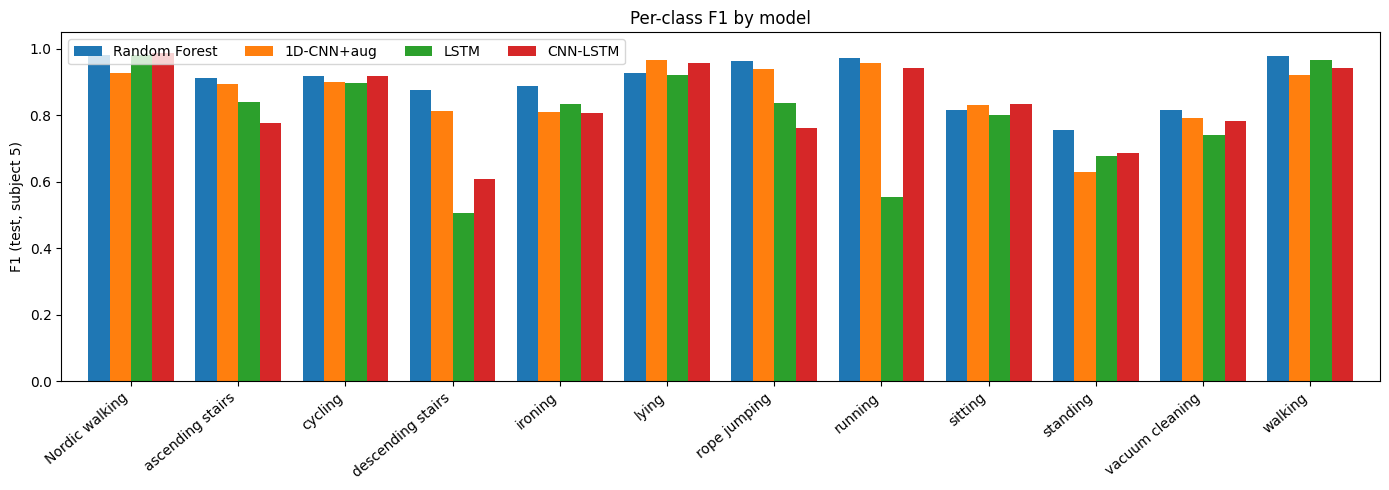

                   Random Forest  1D-CNN+aug   LSTM  CNN-LSTM
Nordic walking             0.983       0.927  0.980     0.988
ascending stairs           0.912       0.895  0.841     0.778
cycling                    0.918       0.900  0.896     0.918
descending stairs          0.875       0.812  0.507     0.610
ironing                    0.888       0.809  0.834     0.807
lying                      0.927       0.966  0.922     0.958
rope jumping               0.965       0.940  0.836     0.763
running                    0.973       0.958  0.554     0.942
sitting                    0.815       0.830  0.802     0.834
standing                   0.755       0.629  0.676     0.686
vacuum cleaning            0.817       0.793  0.742     0.784
walking                    0.980       0.922  0.967     0.942


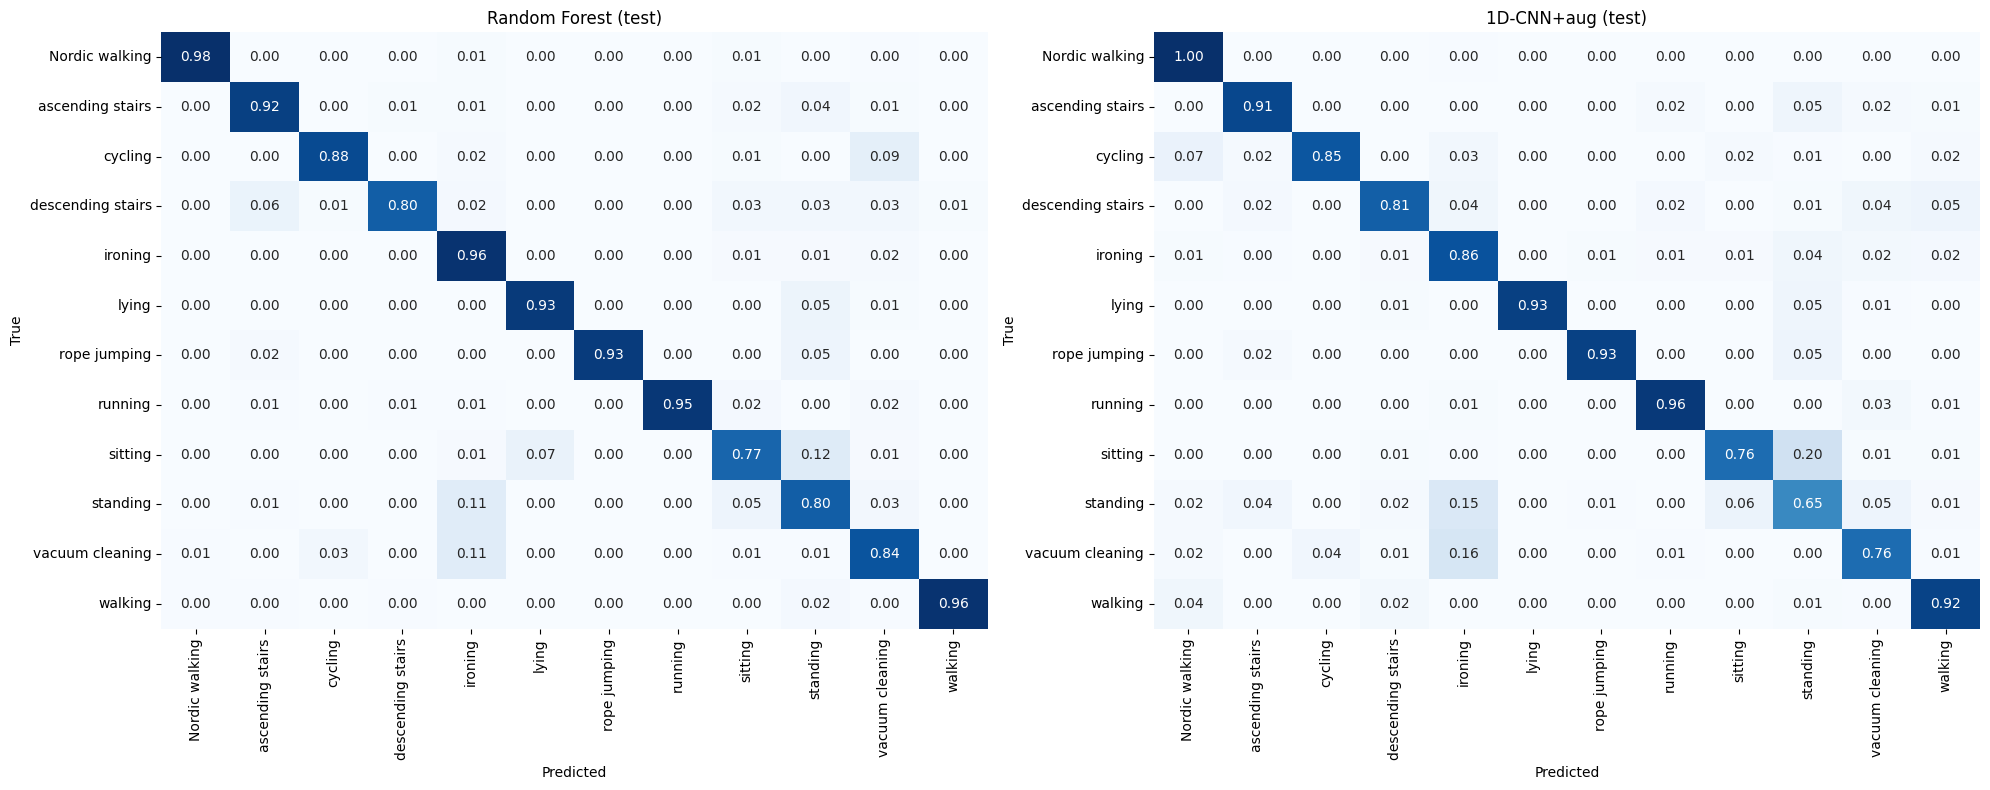

           sitting -> standing           42 windows
   vacuum cleaning -> ironing            31 windows
          standing -> ironing            25 windows
           cycling -> Nordic walking     13 windows
           walking -> Nordic walking     10 windows
           ironing -> standing           10 windows


In [23]:
from sklearn.metrics import precision_recall_fscore_support

preds = {"Random Forest": res_rf['test'][2], "1D-CNN+aug": pred_cnn_aug,
         "LSTM": pred_lstm, "CNN-LSTM": pred_hybrid}

f1 = pd.DataFrame({k: precision_recall_fscore_support(y_test, p, labels=range(12),
                   zero_division=0)[2] for k, p in preds.items()}, index=names)
f1.plot(kind='bar', figsize=(14, 5), width=0.8)
plt.ylabel("F1 (test, subject 5)"); plt.title("Per-class F1 by model")
plt.xticks(rotation=40, ha='right'); plt.ylim(0, 1.05); plt.legend(ncol=4)
plt.tight_layout(); plt.show()
print(f1.round(3))

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
for ax, (nm, p) in zip(axes, [("Random Forest", preds["Random Forest"]),
                              ("1D-CNN+aug", preds["1D-CNN+aug"])]):
    sns.heatmap(confusion_matrix(y_test, p, normalize='true'), annot=True, fmt='.2f',
                cmap='Blues', xticklabels=names, yticklabels=names, ax=ax, cbar=False)
    ax.set_title(f"{nm} (test)"); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout(); plt.show()

# Most common confusions for the CNN
cm = confusion_matrix(y_test, preds["1D-CNN+aug"])
np.fill_diagonal(cm, 0)
for idx in np.dstack(np.unravel_index(np.argsort(cm.ravel())[::-1], cm.shape))[0][:6]:
    print(f"{names[idx[0]]:>18} -> {names[idx[1]]:<18} {cm[idx[0], idx[1]]} windows")

('hand', 0.7005220692928334, 0.6868055363127614)
('chest', 0.8186995728523968, 0.830868993785293)
('ankle', 0.6331276696725202, 0.621801640178996)
('hand+chest', 0.8547698149027053, 0.858121732789071)
('hand+ankle', 0.7674418604651163, 0.7535658256194105)
('chest+ankle', 0.8533459895586142, 0.8260652672264075)
             accuracy  macro_F1
sensors                        
hand            0.701     0.687
chest           0.819     0.831
ankle           0.633     0.622
hand+chest      0.855     0.858
hand+ankle      0.767     0.754
chest+ankle     0.853     0.826
all three       0.863     0.865


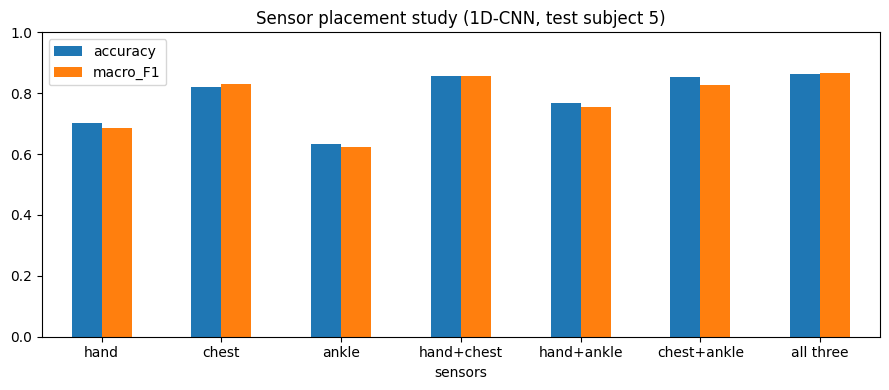

In [24]:
placements = {"hand": slice(0, 6), "chest": slice(6, 12), "ankle": slice(12, 18),
              "hand+chest": np.r_[0:12], "hand+ankle": np.r_[0:6, 12:18],
              "chest+ankle": np.r_[6:18]}
rows = []
for nm, ch in placements.items():
    Xtr_, Xva_, Xte_ = X_train[:, :, ch], X_val[:, :, ch], X_test[:, :, ch]
    tf.keras.utils.set_random_seed(42)
    m = build_cnn_aug(input_shape=(128, Xtr_.shape[2]))
    m.compile(optimizer=keras.optimizers.Adam(5e-4),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    m.fit(Xtr_, y_train, validation_data=(Xva_, y_val), epochs=60, batch_size=64,
          class_weight=class_weight, verbose=0,
          callbacks=[keras.callbacks.EarlyStopping(monitor='val_accuracy', mode='max',
                     patience=12, restore_best_weights=True)])
    p = m.predict(Xte_, verbose=0).argmax(1)
    rows.append((nm, accuracy_score(y_test, p), f1_score(y_test, p, average='macro')))
    print(rows[-1])
rows.append(("all three", accuracy_score(y_test, pred_cnn_aug), f1_score(y_test, pred_cnn_aug, average='macro')))
sp = pd.DataFrame(rows, columns=["sensors", "accuracy", "macro_F1"]).set_index("sensors").round(3)
print(sp)
sp.plot(kind='bar', figsize=(9, 4)); plt.ylim(0, 1); plt.xticks(rotation=0)
plt.title("Sensor placement study (1D-CNN, test subject 5)"); plt.tight_layout(); plt.show()

In [25]:
Fall = extract_features(X)                      # X holds the raw (unscaled) windows
loso = []
for s in sorted(np.unique(subj)):
    te_m, tr_m = subj == s, subj != s
    # Random Forest
    rf_s = RandomForestClassifier(n_estimators=150, class_weight='balanced',
                                  n_jobs=-1, random_state=42).fit(Fall[tr_m], y[tr_m])
    p_rf = rf_s.predict(Fall[te_m])
    # CNN with scaler fit on the training subjects only
    sc = StandardScaler().fit(X[tr_m].reshape(-1, 18))
    f = lambda a: sc.transform(a.reshape(-1, 18)).reshape(a.shape).astype(np.float32)
    cw_s = dict(enumerate(compute_class_weight('balanced', classes=np.unique(y[tr_m]), y=y[tr_m])))
    cw_s = {int(c): w for c, w in zip(np.unique(y[tr_m]), cw_s.values())}
    tf.keras.utils.set_random_seed(42)
    m = build_cnn_aug()
    m.compile(optimizer=keras.optimizers.Adam(5e-4),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    m.fit(f(X[tr_m]), y[tr_m], epochs=15, batch_size=64, class_weight=cw_s, verbose=0)
    p_cnn = m.predict(f(X[te_m]), verbose=0).argmax(1)
    loso.append({"subject": s,
                 "RF_acc": accuracy_score(y[te_m], p_rf), "RF_F1": f1_score(y[te_m], p_rf, average='macro'),
                 "CNN_acc": accuracy_score(y[te_m], p_cnn), "CNN_F1": f1_score(y[te_m], p_cnn, average='macro')})
    print(loso[-1])
loso_df = pd.DataFrame(loso).set_index("subject").round(3)
print(loso_df); print("\nMean ± std:\n", loso_df.agg(['mean', 'std']).round(3))

{'subject': np.int64(1), 'RF_acc': 0.8700828157349897, 'RF_F1': 0.8767286877413931, 'CNN_acc': 0.7779503105590062, 'CNN_F1': 0.7602323019651395}
{'subject': np.int64(2), 'RF_acc': 0.884634266077565, 'RF_F1': 0.8935818793035969, 'CNN_acc': 0.7373588610702013, 'CNN_F1': 0.7253008606095325}
{'subject': np.int64(3), 'RF_acc': 0.9279346210995543, 'RF_F1': 0.6732633407950709, 'CNN_acc': 0.87444279346211, 'CNN_F1': 0.6348090660199056}
{'subject': np.int64(4), 'RF_acc': 0.9162946428571429, 'RF_F1': 0.9164655012486703, 'CNN_acc': 0.7857142857142857, 'CNN_F1': 0.7740766945648316}
{'subject': np.int64(5), 'RF_acc': 0.9008068343616517, 'RF_F1': 0.9026023309224303, 'CNN_acc': 0.8576174655908875, 'CNN_F1': 0.8560096763852365}
{'subject': np.int64(6), 'RF_acc': 0.8826266804550155, 'RF_F1': 0.8054060740990373, 'CNN_acc': 0.8676318510858325, 'CNN_F1': 0.7933161860559523}
{'subject': np.int64(7), 'RF_acc': 0.9383333333333334, 'RF_F1': 0.9279575453365388, 'CNN_acc': 0.9255555555555556, 'CNN_F1': 0.838152

In [28]:
import json
from google.colab import files

# Scaler: same one used for training (train subjects 2,3,4,6,7,8)
tr = np.isin(subj, [2, 3, 4, 6, 7, 8])
sc = StandardScaler().fit(X[tr].reshape(-1, 18))

# Deep models
cnn_aug.save('cnn1d_aug.keras'); lstm.save('lstm.keras'); cnn_lstm.save('cnn_lstm.keras')

# Test metrics on subject 5 (all models use the same test set)
def m(p): return {"acc": float(accuracy_score(y_test, p)),
                  "f1": float(f1_score(y_test, p, average='macro'))}
metrics = {"1D-CNN + augmentation": m(pred_cnn_aug), "CNN-LSTM hybrid": m(pred_hybrid),
           "LSTM": m(pred_lstm), "Random Forest (baseline)": m(res_rf['test'][2])}

# LOSO summary, if you still have the table from Step 10c
try:
    loso = {"Random Forest": {"mean acc": float(loso_df.RF_acc.mean()), "std": float(loso_df.RF_acc.std())},
            "1D-CNN + augmentation": {"mean acc": float(loso_df.CNN_acc.mean()), "std": float(loso_df.CNN_acc.std())}}
except NameError:
    loso = None

json.dump({"mean": sc.mean_.tolist(), "scale": sc.scale_.tolist(),
           "classes": list(names), "channels": list(imu_cols),
           "metrics": metrics, "loso": loso}, open('meta.json', 'w'))

# 8 raw (unscaled) demo windows per activity from the unseen test subject
rng = np.random.default_rng(0)
te_idx = np.where(subj == 5)[0]
demo = np.concatenate([rng.choice(te_idx[y[te_idx] == c], 8, replace=False) for c in range(12)])
np.savez_compressed('demo_windows.npz', X=X[demo], y=y[demo])

!ls -lh *.keras meta.json demo_windows.npz
for f in ['cnn1d_aug.keras', 'lstm.keras', 'cnn_lstm.keras', 'meta.json', 'demo_windows.npz']:
    files.download(f)

-rw-r--r-- 1 root root 1.7M Oct 17 06:55 cnn1d_aug.keras
-rw-r--r-- 1 root root 1.7M Oct 17 06:05 cnn1d.keras
-rw-r--r-- 1 root root 1.3M Oct 17 06:55 cnn_lstm.keras
-rw-r--r-- 1 root root 797K Oct 17 06:55 demo_windows.npz
-rw-r--r-- 1 root root 746K Oct 17 06:55 lstm.keras
-rw-r--r-- 1 root root 1.9K Oct 17 06:55 meta.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>